
# Pooya Valizadeh
CIFAR10 CNN Model

**GitHub:** [PooyaValizadeh](https://github.com/PooyaValizadeh)  
**Kaggle:** [PooyaValizadeh](https://www.kaggle.com/PooyaValizadeh)

---

In [85]:
from tensorflow import keras
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [86]:
(xtrain,ytrain) , (xtest,ytest) = keras.datasets.cifar10.load_data()
x = np.concatenate((xtrain,xtest)) / 255
y = np.concatenate((ytrain,ytest))

In [87]:
y = keras.utils.to_categorical(y)

In [88]:
x.shape , y.shape

((60000, 32, 32, 3), (60000, 10))

In [89]:
from sklearn.model_selection import train_test_split as tts
xtrain , xtest , ytrain , ytest = tts(x,y,test_size=0.15,stratify=y,random_state=26)
xtrain.shape , xtest.shape , ytrain.shape , ytest.shape

((51000, 32, 32, 3), (9000, 32, 32, 3), (51000, 10), (9000, 10))

In [90]:
model = keras.models.Sequential()
model.add(keras.layers.Input(shape=(32,32,3)))
model.add(keras.layers.Conv2D(16,7,activation="relu",padding="SAME"))
model.add(keras.layers.MaxPooling2D(2))
model.add(keras.layers.Conv2D(64,3,activation="relu",padding="SAME"))
model.add(keras.layers.MaxPooling2D(2))
model.add(keras.layers.Flatten())
model.add(keras.layers.Dense(54,activation="relu"))
model.add(keras.layers.Dropout(0.5))
model.add(keras.layers.Dense(10,activation="softmax"))

In [91]:
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_28 (Conv2D)              │ (None, 32, 32, 16)     │         2,368 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_29 (Conv2D)              │ (None, 16, 16, 64)     │         9,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 54)             │       221,238 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 54)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 10)             │           550 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 233,436 (911.86 KB)

 Trainable params: 233,436 (911.86 KB)

 Non-trainable params: 0 (0.00 B)

In [92]:

model1 = keras.models.clone_model(model)
model2 = keras.models.clone_model(model)
model3 = keras.models.clone_model(model)
model4 = keras.models.clone_model(model)


In [93]:
model5 = keras.models.clone_model(model)

In [94]:
model.compile(loss=keras.losses.CategoricalCrossentropy(),optimizer="Adam",metrics=[keras.metrics.CategoricalAccuracy()])
model1.compile(loss=keras.losses.CategoricalCrossentropy(),optimizer="Adam",metrics=[keras.metrics.CategoricalAccuracy()])
model2.compile(loss=keras.losses.CategoricalCrossentropy(),optimizer="Adam",metrics=[keras.metrics.CategoricalAccuracy()])
model3.compile(loss=keras.losses.CategoricalCrossentropy(),optimizer="Adam",metrics=[keras.metrics.CategoricalAccuracy()])
model4.compile(loss=keras.losses.CategoricalCrossentropy(),optimizer="Adam",metrics=[keras.metrics.CategoricalAccuracy()])
model5.compile(loss=keras.losses.CategoricalCrossentropy(),optimizer="Adam",metrics=[keras.metrics.CategoricalAccuracy()])

In [95]:
history = model.fit(xtrain,ytrain,validation_split=0.15,epochs=50,callbacks=[keras.callbacks.EarlyStopping(patience=50,restore_best_weights=True),keras.callbacks.ModelCheckpoint("model.keras")])

Epoch 1/50
1355/1355 ━━━━━━━━━━━━━━━━━━━━ 13s 7ms/step - categorical_accuracy: 0.3256 - loss: 1.8172 - val_categorical_accuracy: 0.4864 - val_loss: 1.4819
Epoch 2/50
1355/1355 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - categorical_accuracy: 0.4228 - loss: 1.5612 - val_categorical_accuracy: 0.5107 - val_loss: 1.3351
Epoch 3/50
1355/1355 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - categorical_accuracy: 0.4653 - loss: 1.4593 - val_categorical_accuracy: 0.5566 - val_loss: 1.2562
Epoch 4/50
1355/1355 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - categorical_accuracy: 0.4970 - loss: 1.3796 - val_categorical_accuracy: 0.5827 - val_loss: 1.1847
Epoch 5/50
1355/1355 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - categorical_accuracy: 0.5209 - loss: 1.3091 - val_categorical_accuracy: 0.5867 - val_loss: 1.1567
Epoch 6/50
1355/1355 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - categorical_accuracy: 0.5428 - loss: 1.2577 - val_categorical_accuracy: 0.5983 - val_loss: 1.1236
Epoch 7/50
1355/1355 ━━━━━━━━━━━━━━━━━━━━ 6s 5ms/step - categorical_accurac

<Axes: >

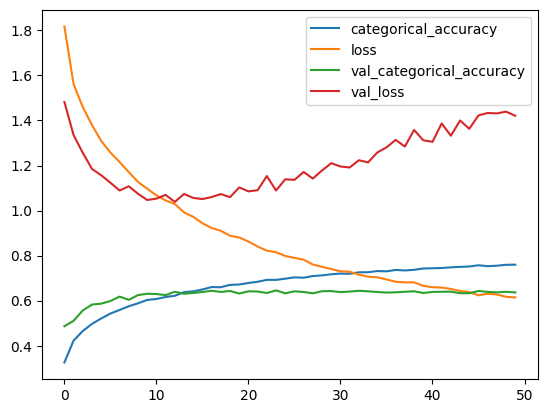

In [96]:
pd.DataFrame(history.history).plot()

In [97]:
model.evaluate(xtest,ytest)

282/282 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - categorical_accuracy: 0.6510 - loss: 1.0082


[1.008155345916748, 0.6510000228881836]

In [98]:
def lr_func(epoch):
    return 1e-3 * (0.95 ** epoch)

In [99]:
def one_cycle(epoch):
    total = 40
    max_lr = 1e-3
    min_lr = 1e-5

    if epoch < total / 2:
        return min_lr + (max_lr - min_lr) * (epoch / (total / 2))
    else:
        return max_lr - (max_lr - min_lr) * ((epoch - total / 2) / (total / 2))

In [100]:
history1 = model1.fit(
    xtrain,
    ytrain,
    validation_split=0.15,
    epochs=50,
    callbacks=[keras.callbacks.EarlyStopping(patience=50,restore_best_weights=True),keras.callbacks.ModelCheckpoint("model1.keras"),keras.callbacks.LearningRateScheduler(schedule=lr_func)])

Epoch 1/50
1355/1355 ━━━━━━━━━━━━━━━━━━━━ 12s 7ms/step - categorical_accuracy: 0.3111 - loss: 1.8541 - val_categorical_accuracy: 0.4729 - val_loss: 1.4784 - learning_rate: 0.0010
Epoch 2/50
1355/1355 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - categorical_accuracy: 0.4196 - loss: 1.5785 - val_categorical_accuracy: 0.5278 - val_loss: 1.3474 - learning_rate: 9.5000e-04
Epoch 3/50
1355/1355 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - categorical_accuracy: 0.4506 - loss: 1.4805 - val_categorical_accuracy: 0.5502 - val_loss: 1.2667 - learning_rate: 9.0250e-04
Epoch 4/50
1355/1355 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - categorical_accuracy: 0.4759 - loss: 1.4112 - val_categorical_accuracy: 0.5580 - val_loss: 1.2206 - learning_rate: 8.5737e-04
Epoch 5/50
1355/1355 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - categorical_accuracy: 0.4964 - loss: 1.3584 - val_categorical_accuracy: 0.5748 - val_loss: 1.2001 - learning_rate: 8.1451e-04
Epoch 6/50
1355/1355 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - categorical_accuracy: 0.5205 - loss: 

In [101]:
history2 = model2.fit(
    xtrain,
    ytrain,
    validation_split=0.15,
    epochs=50,
    callbacks=[
        keras.callbacks.EarlyStopping(patience=50,restore_best_weights=True),keras.callbacks.ModelCheckpoint("model2.keras"),keras.callbacks.LearningRateScheduler(schedule=one_cycle)])

Epoch 1/50
1355/1355 ━━━━━━━━━━━━━━━━━━━━ 12s 6ms/step - categorical_accuracy: 0.1469 - loss: 2.2711 - val_categorical_accuracy: 0.2613 - val_loss: 2.2059 - learning_rate: 1.0000e-05
Epoch 2/50
1355/1355 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - categorical_accuracy: 0.2844 - loss: 1.9662 - val_categorical_accuracy: 0.4064 - val_loss: 1.7463 - learning_rate: 5.9500e-05
Epoch 3/50
1355/1355 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - categorical_accuracy: 0.3640 - loss: 1.7591 - val_categorical_accuracy: 0.4627 - val_loss: 1.5556 - learning_rate: 1.0900e-04
Epoch 4/50
1355/1355 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - categorical_accuracy: 0.4064 - loss: 1.6368 - val_categorical_accuracy: 0.4873 - val_loss: 1.4516 - learning_rate: 1.5850e-04
Epoch 5/50
1355/1355 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - categorical_accuracy: 0.4344 - loss: 1.5572 - val_categorical_accuracy: 0.5222 - val_loss: 1.3774 - learning_rate: 2.0800e-04
Epoch 6/50
1355/1355 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - categorical_accuracy: 0.4677 - lo

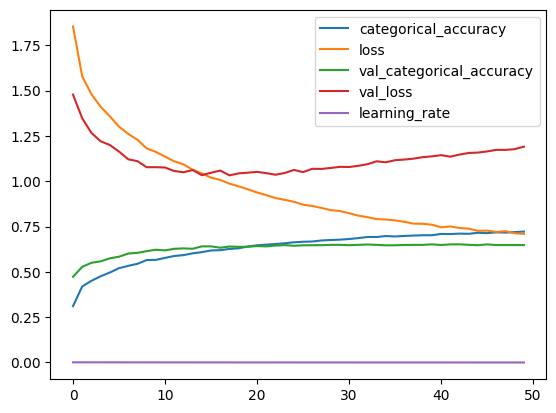

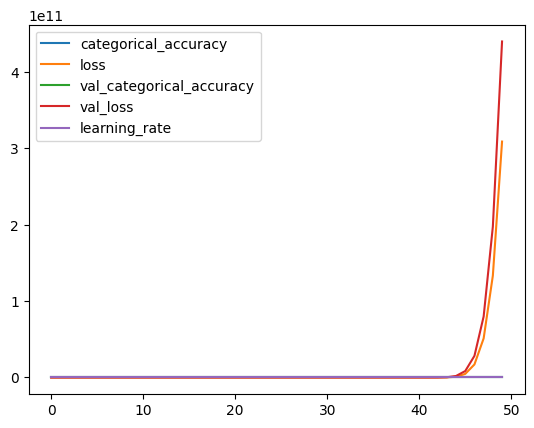

In [102]:
pd.DataFrame(history1.history).plot()
pd.DataFrame(history2.history).plot()
plt.show()

**model without pooling layer**

In [103]:
model3 = keras.Sequential([
    keras.layers.Input(shape=(32, 32, 3)),
    keras.layers.Conv2D(16, (3, 3), padding="same", activation="relu"),
    keras.layers.Conv2D(64, (3, 3), padding="same", activation="relu"),
    keras.layers.Flatten(),
    keras.layers.Dense(54, activation="relu"),
    keras.layers.Dropout(0.3),
    keras.layers.Dense(10, activation="softmax")
])

In [104]:
model3.layers

[<Conv2D name=conv2d_30, built=True>,
 <Conv2D name=conv2d_31, built=True>,
 <Flatten name=flatten_3, built=True>,
 <Dense name=dense_12, built=True>,
 <Dropout name=dropout_3, built=True>,
 <Dense name=dense_13, built=True>]

In [105]:
model3.compile(loss=keras.losses.CategoricalCrossentropy(),optimizer="Adam",metrics=[keras.metrics.CategoricalAccuracy()])

In [106]:
history3 = model3.fit(
    xtrain,
    ytrain,
    validation_split=0.15,
    epochs=50,
    callbacks=[
        keras.callbacks.EarlyStopping(patience=50,restore_best_weights=True),keras.callbacks.ModelCheckpoint("model3.keras")])

Epoch 1/50
1355/1355 ━━━━━━━━━━━━━━━━━━━━ 12s 7ms/step - categorical_accuracy: 0.3518 - loss: 1.7287 - val_categorical_accuracy: 0.5167 - val_loss: 1.3899
Epoch 2/50
1355/1355 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - categorical_accuracy: 0.4545 - loss: 1.4499 - val_categorical_accuracy: 0.5523 - val_loss: 1.2673
Epoch 3/50
1355/1355 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - categorical_accuracy: 0.5006 - loss: 1.3157 - val_categorical_accuracy: 0.5910 - val_loss: 1.1467
Epoch 4/50
1355/1355 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - categorical_accuracy: 0.5376 - loss: 1.2116 - val_categorical_accuracy: 0.5939 - val_loss: 1.1348
Epoch 5/50
1355/1355 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - categorical_accuracy: 0.5686 - loss: 1.1222 - val_categorical_accuracy: 0.6107 - val_loss: 1.0988
Epoch 6/50
1355/1355 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - categorical_accuracy: 0.5915 - loss: 1.0578 - val_categorical_accuracy: 0.6106 - val_loss: 1.0965
Epoch 7/50
1355/1355 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - categorical_accurac

In [107]:
history3.history.keys()

dict_keys(['categorical_accuracy', 'loss', 'val_categorical_accuracy', 'val_loss'])

In [108]:
history3.history["categorical_accuracy3"] , history3.history["loss3"] , history3.history["val_categorical_accuracy3"] , history3.history["val_loss3"] = history3.history.pop("categorical_accuracy") , history3.history.pop("loss") , history3.history.pop("val_categorical_accuracy") , history3.history.pop("val_loss")

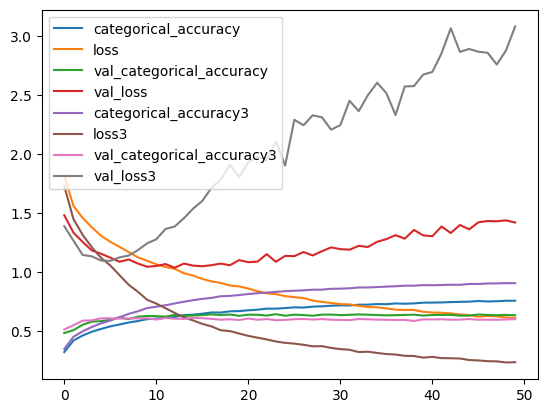

In [109]:
pd.DataFrame(history.history).join(pd.DataFrame(history3.history)).plot()
plt.show()

In [110]:
model4.layers[1].strides = (2,2)
model4.layers[3].strides = (2,2)

model4.layers[1].strides , model4.layers[3].strides

((2, 2), (2, 2))

In [111]:
model5.layers[1].strides = (2,2)
model5.layers[3].strides = (2,2)

model5.layers[1].strides , model5.layers[3].strides

((2, 2), (2, 2))

In [112]:
model4.compile(loss=keras.losses.CategoricalCrossentropy(),optimizer="Adam",metrics=[keras.metrics.CategoricalAccuracy()])
model5.compile(loss=keras.losses.CategoricalCrossentropy(),optimizer="Adam",metrics=[keras.metrics.CategoricalAccuracy()])

In [113]:
history4 = model4.fit(
    xtrain,
    ytrain,
    validation_split=0.15,
    epochs=50,
    callbacks=[
        keras.callbacks.EarlyStopping(patience=50,restore_best_weights=True),keras.callbacks.ModelCheckpoint("model4.keras")])

Epoch 1/50
1355/1355 ━━━━━━━━━━━━━━━━━━━━ 12s 6ms/step - categorical_accuracy: 0.3066 - loss: 1.8614 - val_categorical_accuracy: 0.4563 - val_loss: 1.5156
Epoch 2/50
1355/1355 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - categorical_accuracy: 0.4046 - loss: 1.5965 - val_categorical_accuracy: 0.5163 - val_loss: 1.3553
Epoch 3/50
1355/1355 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - categorical_accuracy: 0.4457 - loss: 1.4899 - val_categorical_accuracy: 0.5367 - val_loss: 1.2857
Epoch 4/50
1355/1355 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - categorical_accuracy: 0.4637 - loss: 1.4369 - val_categorical_accuracy: 0.5583 - val_loss: 1.2268
Epoch 5/50
1355/1355 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - categorical_accuracy: 0.4858 - loss: 1.3784 - val_categorical_accuracy: 0.5715 - val_loss: 1.2046
Epoch 6/50
1355/1355 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - categorical_accuracy: 0.5093 - loss: 1.3284 - val_categorical_accuracy: 0.5827 - val_loss: 1.1795
Epoch 7/50
1355/1355 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - categorical_accurac

In [114]:
history5 = model5.fit(
    xtrain,
    ytrain,
    validation_split=0.15,
    epochs=50,
    callbacks=[
        keras.callbacks.EarlyStopping(patience=50,restore_best_weights=True),keras.callbacks.ModelCheckpoint("model5.keras")])

Epoch 1/50
1355/1355 ━━━━━━━━━━━━━━━━━━━━ 12s 7ms/step - categorical_accuracy: 0.2814 - loss: 1.9336 - val_categorical_accuracy: 0.4710 - val_loss: 1.5159
Epoch 2/50
1355/1355 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - categorical_accuracy: 0.4085 - loss: 1.6089 - val_categorical_accuracy: 0.5114 - val_loss: 1.3736
Epoch 3/50
1355/1355 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - categorical_accuracy: 0.4466 - loss: 1.5079 - val_categorical_accuracy: 0.5431 - val_loss: 1.2866
Epoch 4/50
1355/1355 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - categorical_accuracy: 0.4786 - loss: 1.4301 - val_categorical_accuracy: 0.5587 - val_loss: 1.2244
Epoch 5/50
1355/1355 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - categorical_accuracy: 0.4991 - loss: 1.3663 - val_categorical_accuracy: 0.5667 - val_loss: 1.2251
Epoch 6/50
1355/1355 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - categorical_accuracy: 0.5290 - loss: 1.3049 - val_categorical_accuracy: 0.5925 - val_loss: 1.1404
Epoch 7/50
1355/1355 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - categorical_accurac

In [115]:
history5.history["categorical_accuracy5"] , history5.history["loss5"] , history5.history["val_categorical_accuracy5"] , history5.history["val_loss5"] = history5.history.pop("categorical_accuracy") , history5.history.pop("loss") , history5.history.pop("val_categorical_accuracy") , history5.history.pop("val_loss")

In [116]:
history4.history["categorical_accuracy4"] , history4.history["loss4"] , history4.history["val_categorical_accuracy4"] , history4.history["val_loss4"] = history4.history.pop("categorical_accuracy") , history4.history.pop("loss") , history4.history.pop("val_categorical_accuracy") , history4.history.pop("val_loss")

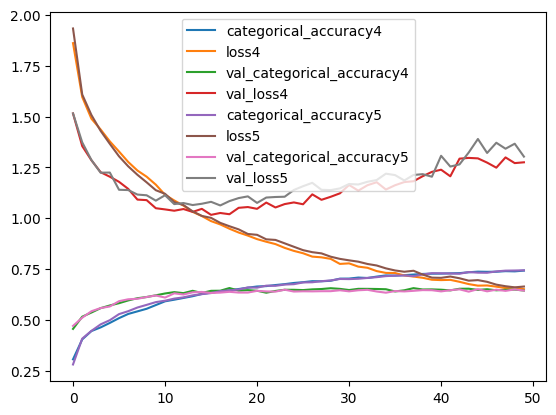

In [117]:
pd.DataFrame(history4.history).join(pd.DataFrame(history5.history)).plot()
plt.show()

In [118]:
app = keras.applications.Xception(include_top=False)
ga_layer = keras.layers.GlobalAveragePooling2D()(app.output)
output = keras.layers.Dense(10,activation="softmax")(ga_layer)
model = keras.Model(app.input,output)

In [119]:
model.summary()

Model: "functional_32"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_10      │ (None, None,      │          0 │ -                 │
│ (InputLayer)        │ None, 3)          │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_conv1        │ (None, None,      │        864 │ input_layer_10[0… │
│ (Conv2D)            │ None, 32)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_conv1_bn     │ (None, None,      │        128 │ block1_conv1[0][… │
│ (BatchNormalizatio… │ None, 32)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_conv1_act    │ (None, None,      │          0 │ block1_conv1_bn[… │
│ (Activation)        │ None, 32)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_conv2        │ (None, None,      │     18,432 │ block1_conv1_act… │
│ (Conv2D)            │ None, 64)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_conv2_bn     │ (None, None,      │        256 │ block1_conv2[0][… │
│ (BatchNormalizatio… │ None, 64)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_conv2_act    │ (None, None,      │          0 │ block1_conv2_bn[… │
│ (Activation)        │ None, 64)         │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_sepconv1     │ (None, None,      │      8,768 │ block1_conv2_act… │
│ (SeparableConv2D)   │ None, 128)        │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_sepconv1_bn  │ (None, None,      │        512 │ block2_sepconv1[… │
│ (BatchNormalizatio… │ None, 128)        │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_sepconv2_act │ (None, None,      │          0 │ block2_sepconv1_… │
│ (Activation)        │ None, 128)        │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_sepconv2     │ (None, None,      │     17,536 │ block2_sepconv2_… │
│ (SeparableConv2D)   │ None, 128)        │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_sepconv2_bn  │ (None, None,      │        512 │ block2_sepconv2[… │
│ (BatchNormalizatio… │ None, 128)        │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_32 (Conv2D)  │ (None, None,      │      8,192 │ block1_conv2_act… │
│                     │ None, 128)        │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_pool         │ (None, None,      │          0 │ block2_sepconv2_… │
│ (MaxPooling2D)      │ None, 128)        │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, None,      │        512 │ conv2d_32[0][0]   │
│ (BatchNormalizatio… │ None, 128)        │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_72 (Add)        │ (None, None,      │          0 │ block2_pool[0][0… │
│                     │ None, 128)        │            │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block3_sepconv1_act │ (None, None,      │          0 │ add_72[0][0]    

 Total params: 20,881,970 (79.66 MB)

 Trainable params: 20,827,442 (79.45 MB)

 Non-trainable params: 54,528 (213.00 KB)

In [120]:
model_2 = keras.models.clone_model(model)

In [121]:
for layer in model.layers:
  layer.trainable = False

In [122]:
model.compile(loss=keras.losses.CategoricalCrossentropy(),optimizer="Adam",metrics=[keras.metrics.CategoricalAccuracy()])

In [123]:
history6 = model.fit(xtrain,ytrain,epochs=10,validation_split=0.15)

Epoch 1/10


/usr/local/lib/python3.13/dist-packages/keras/src/backend/tensorflow/trainer.py:86: UserWarning: The model does not have any trainable weights.
  warnings.warn("The model does not have any trainable weights.")


1355/1355 ━━━━━━━━━━━━━━━━━━━━ 23s 15ms/step - categorical_accuracy: 0.0860 - loss: 2.3056 - val_categorical_accuracy: 0.0771 - val_loss: 2.3054
Epoch 2/10
1355/1355 ━━━━━━━━━━━━━━━━━━━━ 13s 9ms/step - categorical_accuracy: 0.0860 - loss: 2.3056 - val_categorical_accuracy: 0.0771 - val_loss: 2.3054
Epoch 3/10
1355/1355 ━━━━━━━━━━━━━━━━━━━━ 13s 9ms/step - categorical_accuracy: 0.0860 - loss: 2.3056 - val_categorical_accuracy: 0.0771 - val_loss: 2.3054
Epoch 4/10
1355/1355 ━━━━━━━━━━━━━━━━━━━━ 13s 9ms/step - categorical_accuracy: 0.0860 - loss: 2.3056 - val_categorical_accuracy: 0.0771 - val_loss: 2.3054
Epoch 5/10
1355/1355 ━━━━━━━━━━━━━━━━━━━━ 13s 9ms/step - categorical_accuracy: 0.0860 - loss: 2.3056 - val_categorical_accuracy: 0.0771 - val_loss: 2.3054
Epoch 6/10
1355/1355 ━━━━━━━━━━━━━━━━━━━━ 12s 9ms/step - categorical_accuracy: 0.0860 - loss: 2.3056 - val_categorical_accuracy: 0.0771 - val_loss: 2.3054
Epoch 7/10
1355/1355 ━━━━━━━━━━━━━━━━━━━━ 12s 9ms/step - categorical_accuracy: 0

In [124]:
for layer in model_2.layers[:-4]:
  layer.trainable = False

In [125]:
model_2.compile(loss=keras.losses.CategoricalCrossentropy(),optimizer="Adam",metrics=[keras.metrics.CategoricalAccuracy()])

In [126]:
history7 = model_2.fit(xtrain,ytrain,epochs=50,validation_split=0.15)

Epoch 1/50
1355/1355 ━━━━━━━━━━━━━━━━━━━━ 27s 15ms/step - categorical_accuracy: 0.0981 - loss: 2.3029 - val_categorical_accuracy: 0.0976 - val_loss: 2.3026
Epoch 2/50
1355/1355 ━━━━━━━━━━━━━━━━━━━━ 13s 9ms/step - categorical_accuracy: 0.0991 - loss: 2.3028 - val_categorical_accuracy: 0.0983 - val_loss: 2.3028
Epoch 3/50
1355/1355 ━━━━━━━━━━━━━━━━━━━━ 12s 9ms/step - categorical_accuracy: 0.0976 - loss: 2.3027 - val_categorical_accuracy: 0.0973 - val_loss: 2.3028
Epoch 4/50
1355/1355 ━━━━━━━━━━━━━━━━━━━━ 12s 9ms/step - categorical_accuracy: 0.0966 - loss: 2.3028 - val_categorical_accuracy: 0.0973 - val_loss: 2.3027
Epoch 5/50
1355/1355 ━━━━━━━━━━━━━━━━━━━━ 21s 9ms/step - categorical_accuracy: 0.0987 - loss: 2.3028 - val_categorical_accuracy: 0.0973 - val_loss: 2.3027
Epoch 6/50
1355/1355 ━━━━━━━━━━━━━━━━━━━━ 12s 9ms/step - categorical_accuracy: 0.0953 - loss: 2.3028 - val_categorical_accuracy: 0.0974 - val_loss: 2.3027
Epoch 7/50
1355/1355 ━━━━━━━━━━━━━━━━━━━━ 13s 9ms/step - categorical_

In [127]:
print(history6.history.keys())

dict_keys(['categorical_accuracy', 'loss', 'val_categorical_accuracy', 'val_loss'])


In [128]:
history6.history["categorical_accuracy6"] , history6.history["loss6"] , history6.history["val_categorical_accuracy6"] , history6.history["val_loss6"] = history6.history.pop("categorical_accuracy") , history6.history.pop("loss") , history6.history.pop("val_categorical_accuracy") , history6.history.pop("val_loss")
history7.history["categorical_accuracy7"] , history7.history["loss7"] , history7.history["val_categorical_accuracy7"] , history7.history["val_loss7"] = history7.history.pop("categorical_accuracy") , history7.history.pop("loss") , history7.history.pop("val_categorical_accuracy") , history7.history.pop("val_loss")

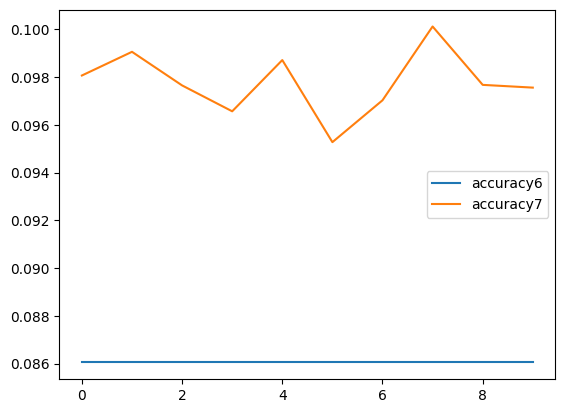

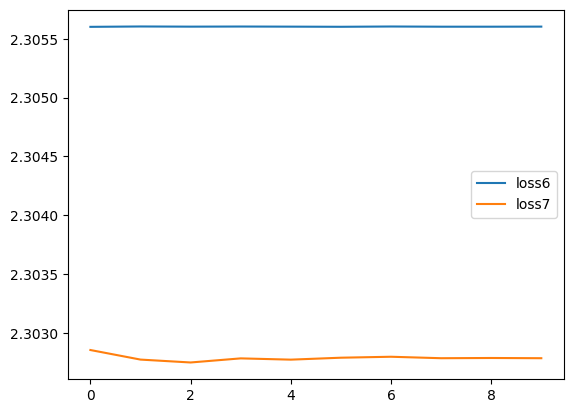

In [132]:
df6 = pd.DataFrame({
    "accuracy6": history6.history["categorical_accuracy6"],
})

df7 = pd.DataFrame({
    "accuracy7": history7.history["categorical_accuracy7"],
})

df6.join(df7).plot()
plt.show()


df8 = pd.DataFrame({
    "loss6": history6.history["loss6"],
})

df9 = pd.DataFrame({
    "loss7": history7.history["loss7"],
})

df8.join(df9).plot()
plt.show()

***همانطور که مشاهده می شود وقتی ما چند لایه از مدل را قابل یادگیری می کنیم مدل دقت بهتری به دست می اورد***